# Week 03 · Feature engineering

Last week ended with an uncomfortable result: judged on the future, Week 1's baselines were barely better than guessing. This week we build features that do better, and we build them so they cannot leak.

By the end of this notebook you will have:

- told apart the two kinds of feature: those computed from one row, and those learned from many
- built four row-wise features from what we know at the moment of purchase
- watched a subtle leak inflate a score, and fixed it
- written your own scikit-learn transformer
- put preprocessing and model into one pipeline
- seen why target encoding needs care, and why logistic regression needs scaling
- let validation decide which features earn their place, then looked at test once

## Setup

In [3]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, "..")
from checkpoints import week_02

RANDOM_STATE = 42
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
ACCENT, WARM, GREY = "#3f51b5", "#e07b39", "#c9cdd6"


def lift(y_true, scores):
    """PR AUC divided by the positive rate: how many times better than guessing."""
    return average_precision_score(y_true, scores) / np.mean(y_true)

## 0. Start where we left off

We load last week's clean table, one row per order, already split by time.

In [5]:
df = week_02()
train, valid, test = (df[df["split"] == part].copy() for part in ["train", "valid", "test"])
print(f"train {len(train):,}   valid {len(valid):,}   test {len(test):,}")

train 57,051   valid 13,801   test 25,352


**The bar to beat.** In Week 2, Week 1's rule and tree scored a lift of **1.57 and 1.65 on validation**, and **1.10 and 1.18 on test**. Every choice this week is made on validation. Test we look at once, at the very end.

## 1. Two kinds of feature

Every feature you will ever build falls into one of two kinds, and the difference decides whether it can leak.

| Kind | Computed from | Example | When it is safe to build |
|---|---|---|---|
| **Row-wise** | One row, on its own | Distance between seller and customer | Anytime. The answer is the same however you split the data. |
| **Learned** | Many rows | A seller's average late rate | Only from training rows, after the split |

A row-wise feature gives the same value for an order whether it sits in train or test. A learned feature does not: it depends on which other rows were used to compute it. That is exactly where leaks come from.

We start with the safe kind.

### Row-wise features

Last week's charts suggested distance and same state. Two more come straight from the data: how many days were promised, and how large the freight cost is compared with the price.

For distance we use the **haversine** formula, the straight-line distance between two points on a sphere:

In [8]:
def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

print(f"São Paulo to Rio de Janeiro: {haversine_km(-23.55, -46.63, -22.91, -43.17):.0f} km")

São Paulo to Rio de Janeiro: 361 km


Now the four features. Each one uses a single row and nothing else, so we can add them to the whole table at once.

In [10]:
def add_row_wise(frame):
    frame = frame.copy()
    frame["distance_km"] = haversine_km(frame["seller_lat"], frame["seller_lng"], frame["customer_lat"], frame["customer_lng"])
    frame["same_state"] = (frame["customer_state"] == frame["seller_state"]).astype(int)
    frame["window_days"] = (frame["order_estimated_delivery_date"] - frame["order_purchase_timestamp"].dt.normalize()).dt.days
    frame["freight_ratio"] = frame["total_freight"] / frame["total_price"]
    return frame

train, valid, test = add_row_wise(train), add_row_wise(valid), add_row_wise(test)
train[["distance_km", "same_state", "window_days", "freight_ratio"]].describe().round(2)

,distance_km,same_state,window_days,freight_ratio
count,56754.00,57051.00,57051.0,57051.00
mean,619.69,0.34,25.5,0.30
std,594.68,0.47,7.7,0.29
min,0.00,0.00,8.0,0.00
25%,227.17,0.00,21.0,0.13
50%,453.31,0.00,25.0,0.22
75%,816.05,1.00,30.0,0.37
max,3387.26,1.00,156.0,5.74


The typical order travels about 450 km, a third stay within one state, and freight costs about a fifth of the price.

### Which of them carry signal?

A quick test before any model: use each feature, alone, as a score, and measure its lift on validation. Some features predict lateness when they are *high*, others when they are *low*, so we try both directions and keep the better one.

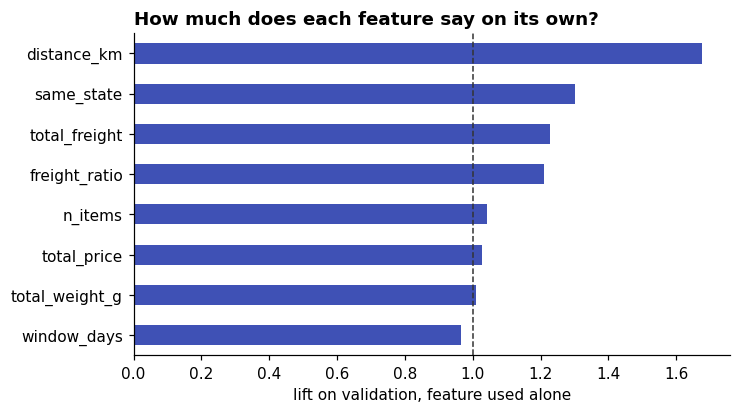

,lift,late when
distance_km,1.675488,high
same_state,1.301735,low
total_freight,1.227649,high
freight_ratio,1.211353,high
n_items,1.041429,low
total_price,1.027066,high
total_weight_g,1.010601,low
window_days,0.964464,high


In [12]:
ROW_WISE = ["distance_km", "same_state", "window_days", "freight_ratio", "total_freight", "total_weight_g", "n_items", "total_price"]

single = {}
for feature in ROW_WISE:
    values = valid[feature].fillna(train[feature].median())
    high, low = lift(valid["is_late"], values), lift(valid["is_late"], -values)
    single[feature] = pd.Series({"lift": max(high, low), "late when": "high" if high >= low else "low"})
single = pd.DataFrame(single).T.sort_values("lift", ascending=False)

ax = single["lift"].astype(float).sort_values().plot.barh(color=ACCENT, figsize=(7, 3.8))
ax.axvline(1, color="#333333", ls="--", lw=1)
ax.set_xlabel("lift on validation, feature used alone")
ax.set_title("How much does each feature say on its own?")
plt.show()
single

Distance leads, followed by same state, freight, and the freight ratio. Weight, price and the number of items say almost nothing on their own. Notice that `window_days` is below 1 on validation: on its own, in this period, the length of the promise says nothing.

A weak feature alone can still help in combination with others, so we keep them all for now. Part 7 decides properly.

## 2. The leak Week 1 promised

In Week 1 we listed three kinds of leak, from obvious to quiet. The quietest was **a statistic computed over the whole dataset**. Here it is.

Some sellers are much more often late than others. So a seller's past late rate sounds like an excellent feature. The question is: computed from which orders?

In [15]:
overall = train["is_late"].mean()

rate_all = df.groupby("seller_id")["is_late"].mean()
rate_train = train.groupby("seller_id")["is_late"].mean()

leaky = valid["seller_id"].map(rate_all).fillna(overall)
honest = valid["seller_id"].map(rate_train).fillna(overall)

print(f"seller late rate from ALL data:   validation lift {lift(valid['is_late'], leaky):.2f}")
print(f"seller late rate from train only: validation lift {lift(valid['is_late'], honest):.2f}")

seller late rate from ALL data:   validation lift 1.89
seller late rate from train only: validation lift 1.21


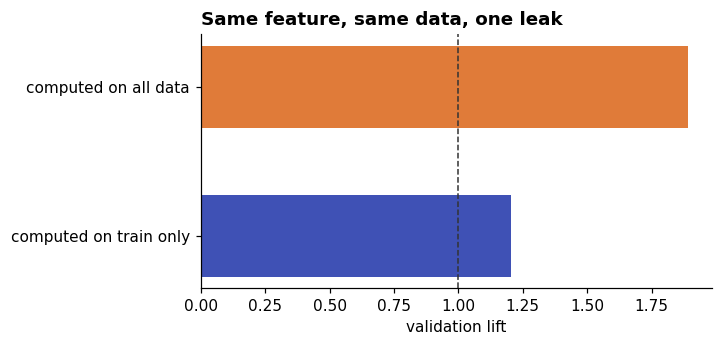

In [16]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["computed on train only", "computed on all data"],
        [lift(valid["is_late"], honest), lift(valid["is_late"], leaky)], color=[ACCENT, WARM], height=0.55)
ax.axvline(1, color="#333333", ls="--", lw=1)
ax.set_xlabel("validation lift")
ax.set_title("Same feature, same data, one leak")
plt.show()

The same feature scores 1.89 when it is computed from all the data, and 1.21 when it is computed honestly. The difference is pure leak: when the rate is computed from all orders, each validation order's own label is already inside its seller's average. The feature partly contains the answer.

Nothing crashed. No warning. It simply looked like a great feature. **Any feature learned from many rows must be learned from the training rows only.**

## 3. Your own transformer

The fix for learned features is a pattern, not a trick. A **transformer** has two methods:

- `fit(X, y)` **learns** something from the training data, and stores it
- `transform(X)` **applies** what was learned, to any data

Learning happens once, on train. Applying happens everywhere. This is the same pattern as the `MedianImputer` class in the [Python refresher](https://evisp.github.io/ml-course-umt/01-toolkit/python-refresher/), and every preprocessing step in scikit-learn follows it.

Let's build one. Last week's promised-versus-actual chart showed that Olist pads its promises. So a useful question is: **how much slack does this promise leave, compared with how long this route usually takes?** The typical time per route must be learned, so it goes in `fit`. The slack is computed in `transform`.

One detail matters here. `fit` may look at the actual delivery dates, because it only ever sees training orders, which are in the past. `transform` must **not**: at the moment of purchase, the delivery has not happened yet.

In [19]:
class RouteSlack(BaseEstimator, TransformerMixin):
    """Days of slack in the promise, compared with the typical delivery time on this route."""

    def fit(self, X, y=None):
        purchase_day = X["order_purchase_timestamp"].dt.normalize()
        days_taken = (X["order_delivered_customer_date"].dt.normalize() - purchase_day).dt.days
        route = X["seller_state"] + " > " + X["customer_state"]
        self.typical_days_ = days_taken.groupby(route).median()
        self.overall_days_ = days_taken.median()
        return self

    def transform(self, X):
        route = X["seller_state"] + " > " + X["customer_state"]
        typical = route.map(self.typical_days_).fillna(self.overall_days_)
        promised = (X["order_estimated_delivery_date"] - X["order_purchase_timestamp"].dt.normalize()).dt.days
        return pd.DataFrame({"slack_days": promised - typical}, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array(["slack_days"])

Fit on train, apply to validation:

In [21]:
slack = RouteSlack().fit(train)

print(f"routes learned: {len(slack.typical_days_)}")
print(f"typical São Paulo to Rio de Janeiro: {slack.typical_days_['SP > RJ']:.0f} days")
slack.transform(valid).describe().round(1)

routes learned: 369
typical São Paulo to Rio de Janeiro: 13 days


,slack_days
count,13801.0
mean,12.3
std,6.3
min,-21.0
25%,8.0
50%,11.0
75%,16.0
max,143.0


A typical São Paulo to Rio parcel takes 13 days, and the median validation order is promised 11 days more than its route usually needs. Olist's padding, in one number per order.

Notice that the transformer holds what it learned in attributes ending in an underscore: `typical_days_`, `overall_days_`. That is the scikit-learn convention for "learned during fit".

## 4. The pipeline

Doing each step by hand, as in Part 2, is how leaks creep in: one forgotten `fit` on the wrong data is enough. A **pipeline** makes it structurally impossible. It holds every preprocessing step and the model in one object. Calling `fit` on it fits every step on the data you pass, in order. Calling `predict` applies them all, using only what was learned during fit.

Different columns need different treatment, so we use a `ColumnTransformer` to route them:

| Columns | Treatment |
|---|---|
| The eight row-wise numbers | Fill gaps with the training median, then scale |
| Customer and seller state | One-hot encode: 27 states each, a manageable number of columns |

In [24]:
numeric = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

prep = ColumnTransformer([
    ("numeric", numeric, ROW_WISE),
    ("states", OneHotEncoder(handle_unknown="ignore"), ["customer_state", "seller_state"]),
])

model = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

model.fit(train, train["is_late"])
print(f"validation lift: {lift(valid['is_late'], model.predict_proba(valid)[:, 1]):.2f}")

validation lift: 2.34


A validation lift of **2.34**, against 1.57 and 1.65 for Week 1's baselines on the same data. The row-wise features are doing real work.

And notice what we did *not* do: we never computed a median or a mean by hand, and never touched validation during fitting. The imputer's medians and the scaler's means live inside the pipeline, learned from train. That is the whole point.

## 5. Target encoding, naive and right

States have 27 values each, so one-hot encoding is fine. Sellers have almost three thousand. One-hot would create three thousand columns, most of them nearly empty.

**Target encoding** replaces each seller with a single number: its late rate. It is a learned feature, so it must come from training rows. But there is a second, subtler trap. If each training order is encoded using a rate that *includes its own label*, the model learns to trust the feature far too much.

Let's see it. First the naive way: compute each seller's rate on the training data, and use it to encode those same training rows.

In [27]:
def with_seller(frame, rates):
    return frame.assign(seller_rate=frame["seller_id"].map(rates).fillna(overall))

def seller_model():
    prep = ColumnTransformer([
        ("numeric", numeric, ROW_WISE + ["seller_rate"]),
        ("states", OneHotEncoder(handle_unknown="ignore"), ["customer_state", "seller_state"]),
    ])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])

naive_train = with_seller(train, rate_train)
naive_valid = with_seller(valid, rate_train)
naive = seller_model().fit(naive_train, train["is_late"])

print(f"naive encoding: train lift {lift(train['is_late'], naive.predict_proba(naive_train)[:, 1]):.2f}, "
      f"validation lift {lift(valid['is_late'], naive.predict_proba(naive_valid)[:, 1]):.2f}")

naive encoding: train lift 3.97, validation lift 1.74


A training lift near 4 and a validation lift far below it. The model has learned that `seller_rate` is almost the answer, because on training rows it partly *is*: each row's own label is inside its seller's average. On new orders, it is not.

The right way is **cross-fitting**. The training rows are split into folds, and each row is encoded using a rate computed from the *other* folds only, so no row ever sees its own label. scikit-learn's `TargetEncoder` does exactly this inside `fit_transform`.

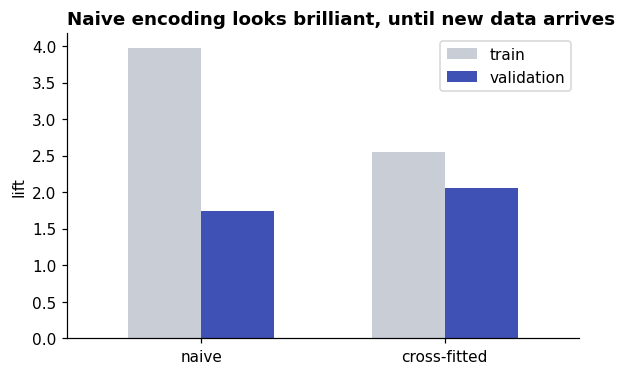

,train,validation
naive,3.97,1.74
cross-fitted,2.54,2.06


In [29]:
encoder = TargetEncoder(random_state=RANDOM_STATE)
fair_train = train.assign(seller_rate=encoder.fit_transform(train[["seller_id"]], train["is_late"]).ravel())
fair_valid = valid.assign(seller_rate=encoder.transform(valid[["seller_id"]]).ravel())
fair = seller_model().fit(fair_train, train["is_late"])

comparison = pd.DataFrame({
    "train": [lift(train["is_late"], naive.predict_proba(naive_train)[:, 1]),
              lift(train["is_late"], fair.predict_proba(fair_train)[:, 1])],
    "validation": [lift(valid["is_late"], naive.predict_proba(naive_valid)[:, 1]),
                   lift(valid["is_late"], fair.predict_proba(fair_valid)[:, 1])],
}, index=["naive", "cross-fitted"])

ax = comparison.plot.bar(color=[GREY, ACCENT], rot=0, figsize=(6, 3.6), width=0.6)
ax.set_ylabel("lift")
ax.set_title("Naive encoding looks brilliant, until new data arrives")
plt.show()
comparison.round(2)

Cross-fitted encoding gives a lower training score, and a higher validation score. That is what honesty looks like: the gap between train and validation shrinks, because the model is no longer fooled by its own labels.

Even so, compare with Part 4: without any seller feature, validation was 2.34. With it, done properly, it is lower. Almost three thousand sellers is a lot to learn from, and many have only a handful of orders. Some features, even done right, do not earn their place. Part 7 checks this properly.

## 6. Why logistic regression needs scaling

Our numeric features live on very different scales: distance in hundreds of kilometres, same state as 0 or 1, freight ratio around 0.2. Logistic regression learns by gradient steps, and features on wildly different scales make those steps inefficient. Remove the scaler and see.

In [32]:
def fit_and_report(scale, label):
    steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    prep = ColumnTransformer([
        ("numeric", Pipeline(steps), ROW_WISE),
        ("states", OneHotEncoder(handle_unknown="ignore"), ["customer_state", "seller_state"]),
    ])
    pipe = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=300, class_weight="balanced"))])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        pipe.fit(train, train["is_late"])
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    print(f"{label:16} converged: {converged!s:6} validation lift: {lift(valid['is_late'], pipe.predict_proba(valid)[:, 1]):.2f}")

fit_and_report(scale=True, label="with scaling")
fit_and_report(scale=False, label="without scaling")

with scaling     converged: True   validation lift: 2.34
without scaling  converged: False  validation lift: 2.28


Without scaling, the optimiser runs out of steps before it finds the best weights. You get a model, and a warning that is easy to ignore.

Scaling has a second benefit: once every feature has the same scale, the **coefficients become comparable**. A larger coefficient means a larger effect for a typical change in that feature.

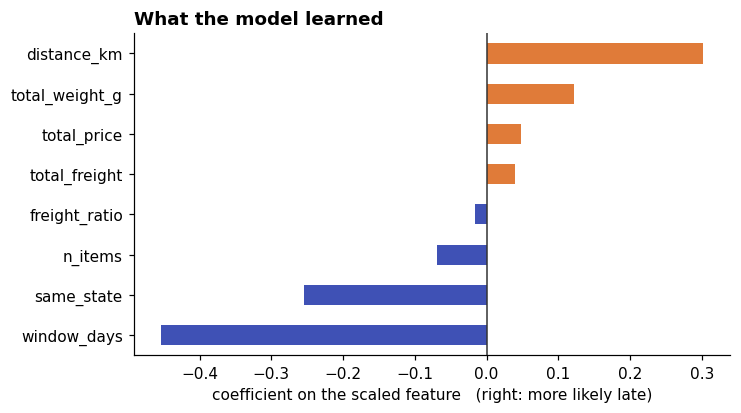

In [34]:
names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model.named_steps["model"].coef_[0], index=names)
numeric_coefs = coefs[[f"numeric__{f}" for f in ROW_WISE]].rename(lambda n: n.replace("numeric__", "")).sort_values()

ax = numeric_coefs.plot.barh(color=[WARM if c > 0 else ACCENT for c in numeric_coefs], figsize=(7, 3.8))
ax.axvline(0, color="#333333", lw=1)
ax.set_xlabel("coefficient on the scaled feature   (right: more likely late)")
ax.set_title("What the model learned")
plt.show()

Read it from the ends. **A longer promise** pushes strongly towards *on time*: padding works. **Distance** pushes towards *late*, and **staying within one state** towards *on time*. Weight pushes a little towards late. The rest barely matter once the others are known.

Look at `window_days`. In Part 1 it was the *weakest* feature on its own, below 1. Here it has the *strongest* coefficient. A long promise only tells you something once the model also knows how far the parcel travels and whether it crosses a state line. That is the answer to the question in Part 1: useless alone does not mean useless in a model.

Every one of these agrees with last week's charts. When a model's coefficients make sense to someone who knows the business, that is a good sign. When they do not, look again before trusting the score.

## 7. A feature must earn its place

We now have several candidate additions to the row-wise model: the route slack from Part 3, the category, and the seller. Each sounds reasonable. The only fair way to decide is to add each one to the base model **on its own**, and judge it **on validation**.

In [37]:
def build(extra=None, estimator=None):
    parts = [
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), ROW_WISE),
        ("states", OneHotEncoder(handle_unknown="ignore"), ["customer_state", "seller_state"]),
    ]
    if extra == "route slack":
        route_columns = ["order_purchase_timestamp", "order_estimated_delivery_date",
                         "order_delivered_customer_date", "seller_state", "customer_state"]
        parts.append(("slack", Pipeline([("slack", RouteSlack()), ("scale", StandardScaler())]), route_columns))
    elif extra == "category":
        parts.append(("category", TargetEncoder(random_state=RANDOM_STATE), ["category"]))
    elif extra == "seller":
        parts.append(("seller", TargetEncoder(random_state=RANDOM_STATE), ["seller_id"]))
    estimator = estimator or LogisticRegression(max_iter=2000, class_weight="balanced")
    return Pipeline([("prep", ColumnTransformer(parts)), ("model", estimator)])

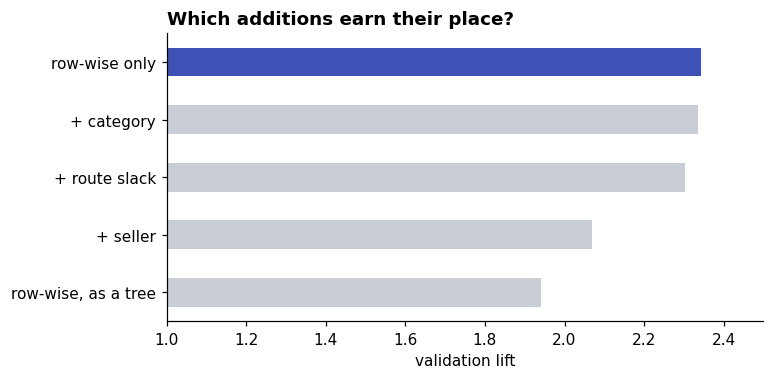

row-wise only          2.34
+ route slack          2.30
+ category             2.34
+ seller               2.07
row-wise, as a tree    1.94
dtype: float64

In [38]:
candidates = {
    "row-wise only": build(),
    "+ route slack": build("route slack"),
    "+ category": build("category"),
    "+ seller": build("seller"),
    "row-wise, as a tree": build(estimator=DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=RANDOM_STATE)),
}

scores = {}
for name, pipe in candidates.items():
    pipe.fit(train, train["is_late"])
    scores[name] = lift(valid["is_late"], pipe.predict_proba(valid)[:, 1])
scores = pd.Series(scores)

ax = scores.sort_values().plot.barh(color=[ACCENT if s == scores.max() else GREY for s in scores.sort_values()], figsize=(7, 3.4))
ax.set_xlim(1, 2.5)
ax.set_xlabel("validation lift")
ax.set_title("Which additions earn their place?")
plt.show()
scores.round(2)

None of the learned additions clearly beats the plain row-wise model. The category is a tie at best, and the route slack and the seller both make validation worse. The tree, on exactly the same features, loses too. Why trees behave this way on data like ours is a question for Block 2.

This is a result worth being proud of, not disappointed by. **Simpler won, and we know it because we tested it on data the model never saw**, rather than because it felt clever. So the chosen model is the row-wise logistic regression from Part 4.

### One look at test

Every decision has been made. Now, and only now, we score the chosen model on test, once.

test lift: 1.87


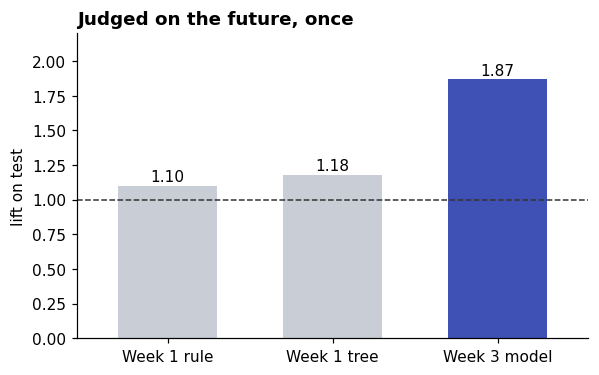

In [40]:
final_lift = lift(test["is_late"], model.predict_proba(test)[:, 1])
print(f"test lift: {final_lift:.2f}")

progress = pd.Series({
    "Week 1 rule": 1.10,
    "Week 1 tree": 1.18,
    "Week 3 model": final_lift,
})
ax = progress.plot.bar(color=[GREY, GREY, ACCENT], rot=0, figsize=(6, 3.6), width=0.6)
ax.axhline(1, color="#333333", ls="--", lw=1)
for i, value in enumerate(progress):
    ax.text(i, value + 0.03, f"{value:.2f}", ha="center")
ax.set_ylabel("lift on test")
ax.set_ylim(0, 2.2)
ax.set_title("Judged on the future, once")
plt.show()

A test lift of **1.87**, against 1.10 and 1.18 for Week 1's baselines on the same future months. Lower than the 2.34 on validation, as we expected after Week 2: the test months are calmer and different. But the improvement is real, and it held on data nobody looked at while making choices.

## 8. Ready for next week

Week 4 evaluates this exact model in depth: where it fails, for whom, and at which threshold. The checkpoint module now has two functions for that. Let's confirm they match what we built.

In [43]:
from checkpoints import week_03, week_03_pipeline

check = week_03()
check_train = check[check["split"] == "train"]
check_valid = check[check["split"] == "valid"]

same_features = np.allclose(check_train["distance_km"].fillna(-1), train["distance_km"].fillna(-1))
chosen = week_03_pipeline().fit(check_train, check_train["is_late"])
same_score = abs(lift(check_valid["is_late"], chosen.predict_proba(check_valid)[:, 1])
                 - lift(valid["is_late"], model.predict_proba(valid)[:, 1])) < 1e-9

print("same features:", same_features)
print("same model:   ", same_score)

same features: True
same model:    True


## What we learned

- **Two kinds of feature.** Row-wise features, from one row, are safe anywhere. Learned features, from many rows, must be learned from training rows only.
- **A statistic over the whole dataset leaks.** The seller rate went from 1.21 to 1.89 on validation, from nothing but where it was computed.
- **Transformers learn in `fit` and apply in `transform`.** `fit` may use the past, `transform` must only use what exists at prediction time.
- **Pipelines make leakage structurally impossible.** Every learned step is fitted on whatever you pass to `fit`, and nothing else.
- **Target encoding needs cross-fitting.** Otherwise each row sees its own label, and the model trusts the feature far too much.
- **Scale for logistic regression.** It converges, and its coefficients become readable.
- **A feature must earn its place, on validation.** Here the simplest model won, and test confirmed it once: 1.87, up from 1.10.

**For next week:** a lift of 1.87 is a summary. Week 4 asks what it hides: at which threshold we should act, which orders the model gets wrong, and whether it fails some customers much more than others.